# Karen · Aprendizaje métrico con dígitos

Esta adaptación utiliza exclusivamente el conjunto Digits, incluido en scikit-learn. Compara un espacio aprendido mediante Triplet Loss con una línea base de píxeles normalizados. Ajuste con clases 0–4, calibración con 5–6 y evaluación con 7–9. Se evalúan 20 galerías y consultas diferentes por episodio. Las consultas pueden repetirse entre episodios, por lo que la suma de 1.200 consultas no equivale a 1.200 imágenes distintas. En Colab elige Entorno de ejecución > Ejecutar todo.

## Datos y configuración

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.datasets import load_digits
from sklearn.metrics import confusion_matrix

ROOT = Path.cwd()
OUT = ROOT / "resultados_metrica"
OUT.mkdir(exist_ok=True)
SEMILLA = 211
torch.manual_seed(SEMILLA)
torch.set_num_threads(2)
rng = np.random.default_rng(SEMILLA)
datos = load_digits()
pixeles = datos.data.astype(np.float32) / 16
etiquetas = datos.target
X = torch.tensor(pixeles)
grupos = {c: np.flatnonzero(etiquetas == c) for c in range(10)}
assert set(range(5)).isdisjoint([5,6,7,8,9])

## Codificador y Triplet Loss

In [2]:
# Codificador compartido
class Codificador(nn.Module):
    def __init__(self):
        super().__init__()
        self.capas = nn.Sequential(nn.Linear(64,128), nn.ReLU(), nn.Linear(128,32))
    def forward(self, lote):
        return F.normalize(self.capas(lote), dim=1)

red = Codificador()
opt = torch.optim.Adam(red.parameters(), lr=0.001)
perdida = nn.TripletMarginLoss(margin=0.25)
historial = []
for epoca in range(30):
    errores = []
    for paso in range(10):
        a, p, n = [], [], []
        for _ in range(64):
            ca, cn = rng.choice(5,2,replace=False)
            ia, ip = rng.choice(grupos[ca],2,replace=False)
            a.append(ia)
            p.append(ip)
            n.append(rng.choice(grupos[cn]))
        opt.zero_grad()
        costo = perdida(red(X[a]),red(X[p]),red(X[n]))
        costo.backward()
        opt.step()
        errores.append(costo.item())
    historial.append(float(np.mean(errores)))
red.eval()
with torch.no_grad():
    aprendidos = red(X).numpy()
crudos = pixeles / np.linalg.norm(pixeles,axis=1,keepdims=True)
assert np.isfinite(aprendidos).all()
assert np.allclose(np.linalg.norm(aprendidos,axis=1),1,atol=1e-5)
print("Imágenes de ajuste:", sum(len(grupos[c]) for c in range(5)))
print("Triplet Loss inicial/final:", historial[0], historial[-1])

Imágenes de ajuste: 901
Triplet Loss inicial/final: 0.05865665320307016 0.0001566038466989994


## Calibración y episodios de prueba

In [3]:
# Protocolo de episodios
def episodio(clases, generador):
    soporte, consultas, verdad = [], [], []
    for c in clases:
        orden = generador.permutation(grupos[c])
        soporte.append(orden[:5])
        consultas.extend(orden[5:25])
        verdad.extend([c]*20)
    assert not set(np.ravel(soporte)).intersection(consultas)
    return np.asarray(soporte),np.asarray(consultas),np.asarray(verdad),np.asarray(clases)

def distancias(representaciones, episodio_actual, shots):
    soporte, consultas, verdad, clases = episodio_actual
    prototipos = representaciones[soporte[:,:shots]].mean(axis=1)
    prototipos /= np.linalg.norm(prototipos,axis=1,keepdims=True)
    d = np.linalg.norm(representaciones[consultas,None,:]-prototipos[None,:,:],axis=2)
    return d,verdad,clases

def medir(d, verdad, clases, umbral):
    iguales = verdad[:,None] == clases[None,:]
    pred = clases[d.argmin(axis=1)]
    return dict(aciertos=int((pred==verdad).sum()), consultas=len(verdad),
        FA=int((d[~iguales]<=umbral).sum()), diferentes=int((~iguales).sum()),
        FR=int((d[iguales]>umbral).sum()), iguales=int(iguales.sum()))

calibracion = episodio([5,6],np.random.default_rng(900))
episodios = [episodio([7,8,9],np.random.default_rng(1000+i)) for i in range(20)]
filas = []
for nombre, vectores in [("Píxeles",crudos),("Siamesa",aprendidos)]:
    for shots in [1,5]:
        d,v,c = distancias(vectores,calibracion,shots)
        umbrales = np.linspace(0,2,201)
        costos=[]
        for t in umbrales:
            m=medir(d,v,c,t)
            costos.append(m["FA"]/m["diferentes"]+m["FR"]/m["iguales"])
        umbral=float(umbrales[np.argmin(costos)])
        mediciones=[]
        for e in episodios:
            dt,vt,ct=distancias(vectores,e,shots)
            mediciones.append(medir(dt,vt,ct,umbral))
        aciertos=sum(m["aciertos"] for m in mediciones)
        total=sum(m["consultas"] for m in mediciones)
        fila=dict(metodo=nombre,referencias=shots,umbral=umbral,
            aciertos=aciertos,consultas=total,exactitud=aciertos/total,
            FAR=sum(m["FA"] for m in mediciones)/sum(m["diferentes"] for m in mediciones),
            FRR=sum(m["FR"] for m in mediciones)/sum(m["iguales"] for m in mediciones))
        filas.append(fila)
        if nombre=="Siamesa":
            dt,vt,ct=distancias(vectores,episodios[0],shots)
            cm=confusion_matrix(vt,ct[dt.argmin(axis=1)],labels=ct)
            fig,ax=plt.subplots(figsize=(3.8,3.2))
            ax.imshow(cm,cmap="Purples")
            for (i,j),valor in np.ndenumerate(cm):
                ax.text(j,i,str(valor),ha="center",va="center")
            ax.set(xticks=range(3),yticks=range(3),xticklabels=ct,yticklabels=ct,
                xlabel="Asignación",ylabel="Clase",title=f"Primer episodio · {shots} referencia(s)")
            fig.tight_layout()
            fig.savefig(OUT/f"matriz_{shots}.png",dpi=160)
            plt.close(fig)
print(json.dumps(filas,indent=2,ensure_ascii=False))
(OUT/"resumen_metrica.json").write_text(json.dumps(dict(
    semilla=SEMILLA,clases_ajuste=[0,1,2,3,4],clases_calibracion=[5,6],
    clases_prueba=[7,8,9],episodios=20,historial=historial,resultados=filas),
    indent=2,ensure_ascii=False),encoding="utf8")
fig,axs=plt.subplots(1,2,figsize=(9,3.2))
axs[0].plot(range(1,31),historial,color="#75507b")
axs[0].set(xlabel="Época",ylabel="Triplet Loss media",title="Ajuste en clases 0–4")
pos=np.arange(2)
for i,nombre in enumerate(["Píxeles","Siamesa"]):
    valores=[f["exactitud"] for f in filas if f["metodo"]==nombre]
    axs[1].bar(pos+i*0.32,valores,width=0.32,label=nombre)
axs[1].set(xticks=pos+0.16,xticklabels=["1 referencia","5 referencias"],
    ylim=(0,1),ylabel="Proporción de aciertos",title="Promedio de 20 episodios")
axs[1].legend()
fig.tight_layout()
fig.savefig(OUT/"comparacion_metrica.png",dpi=160)
plt.close(fig)
print("Experimento de dígitos finalizado.")

[
  {
    "metodo": "Píxeles",
    "referencias": 1,
    "umbral": 0.75,
    "aciertos": 901,
    "consultas": 1200,
    "exactitud": 0.7508333333333334,
    "FAR": 0.4075,
    "FRR": 0.18333333333333332
  },
  {
    "metodo": "Píxeles",
    "referencias": 5,
    "umbral": 0.59,
    "aciertos": 1096,
    "consultas": 1200,
    "exactitud": 0.9133333333333333,
    "FAR": 0.15375,
    "FRR": 0.175
  },
  {
    "metodo": "Siamesa",
    "referencias": 1,
    "umbral": 0.88,
    "aciertos": 727,
    "consultas": 1200,
    "exactitud": 0.6058333333333333,
    "FAR": 0.16041666666666668,
    "FRR": 0.5175
  },
  {
    "metodo": "Siamesa",
    "referencias": 5,
    "umbral": 1.01,
    "aciertos": 892,
    "consultas": 1200,
    "exactitud": 0.7433333333333333,
    "FAR": 0.4083333333333333,
    "FRR": 0.1575
  }
]


Experimento de dígitos finalizado.


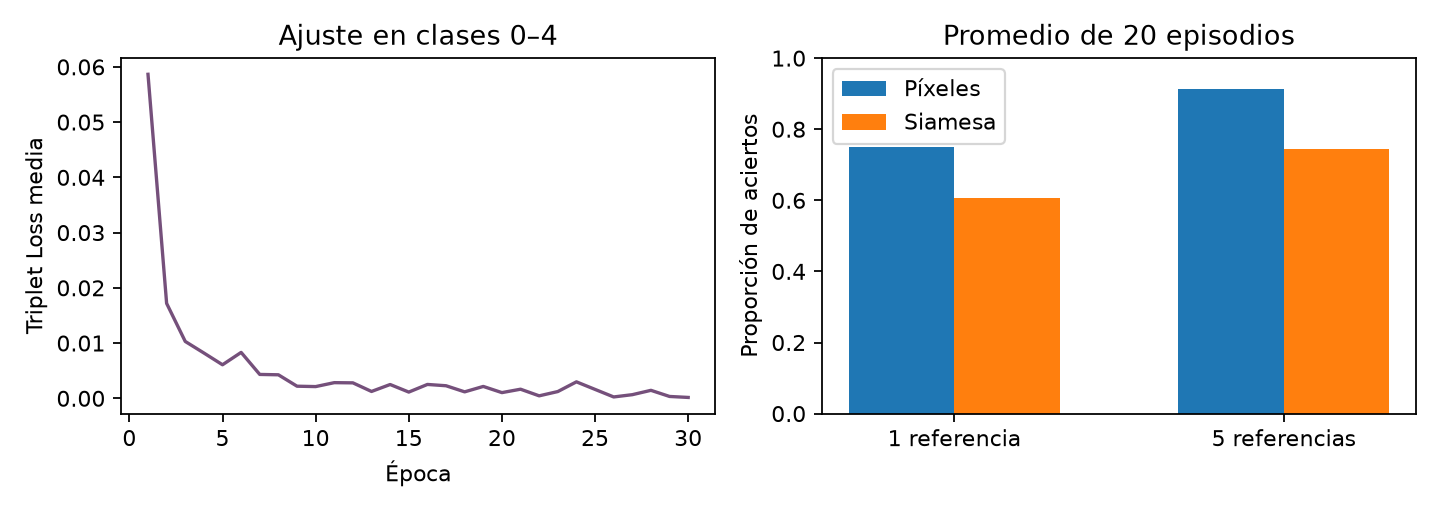

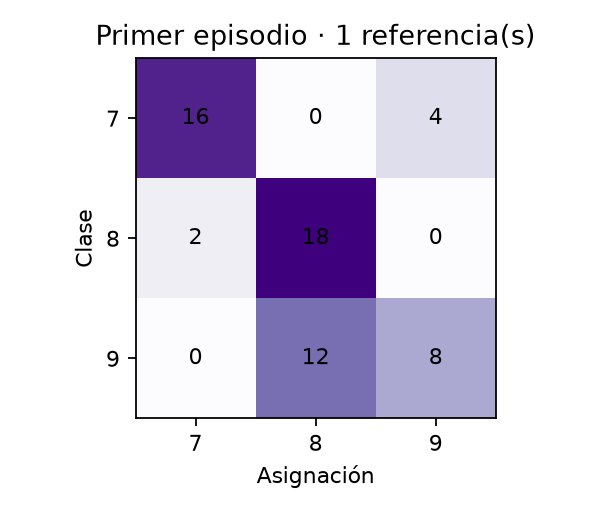

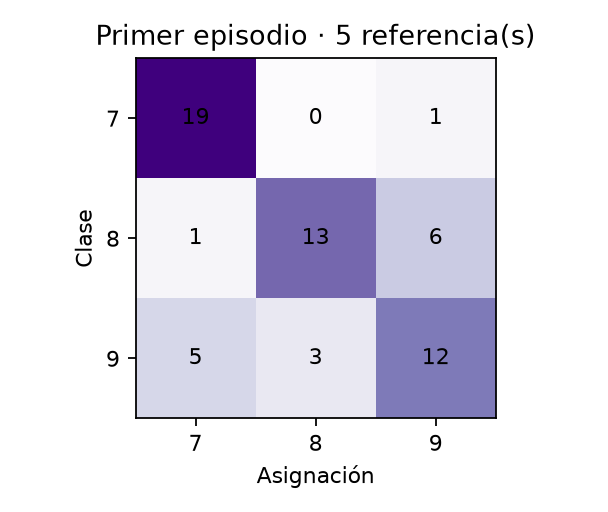

In [4]:
from IPython.display import display, Image
for nombre in ['comparacion_metrica.png','matriz_1.png','matriz_5.png']:
    display(Image(filename=str(OUT / nombre)))

## Lectura crítica
Más referencias mejoran los aciertos medios de ambas representaciones en esta partición. La línea base de píxeles supera al codificador aprendido, pese a que la pérdida de entrenamiento termina cerca de cero. La selección de clases para ajustar limita la transferencia. Los umbrales se eligen en calibración, separados de la prueba. Zero-shot se explica en el informe y queda fuera de las condiciones ejecutadas.

Referencias
- Scikit-learn developers. load_digits. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html
- PyTorch contributors. TripletMarginLoss. https://docs.pytorch.org/docs/stable/generated/torch.nn.TripletMarginLoss.html
- Snell, Swersky y Zemel (2017). Prototypical networks for few-shot learning.

## Alcance de las medidas
La exactitud usa la clase del prototipo más cercano en un conjunto cerrado. FAR y FRR evalúan aceptación por umbral y tienen denominadores diferentes. La comparación entre una y cinco referencias cambia el prototipo y el umbral, por lo que deben revisarse ambas tasas. Las cifras describen una semilla de entrenamiento y tres clases de prueba; los 20 episodios reutilizan imágenes.

La ejecución local fue reproducida en Google Colab el 4 de noviembre de 2026. El repositorio incluye la captura de evidencia. Esta práctica usa exclusivamente dígitos. Su aceptación como adaptación de la consigna facial depende de la profesora.